# Telecom Customer Churn Prediction

## 1. Data Loading and Cleaning

In [23]:
import numpy as np
import pandas as pd

raw = pd.read_csv("../datasets/telco.csv")

print(f"\nMissing Values Count\n{raw.isnull().sum()}")

print(f"\nData Types\n{raw.dtypes}\n")

print(f"Duplicate rows: {raw.duplicated().sum()}")

complete = raw.dropna(subset = [
    'customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
    'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
    'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'
]) 

complete["TotalCharges"] = pd.to_numeric(raw["TotalCharges"], errors="coerce")

X = complete.drop(columns = ["Churn", "customerID"])
y = complete["Churn"].map({"No": 0, "Yes": 1}) 



Missing Values Count
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Data Types
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod  

## 2. Exploratory Data Analysis

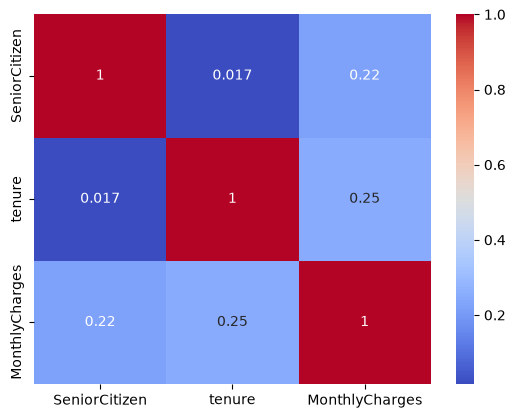

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt

numeric_data = raw.select_dtypes(include="number")

correlation = numeric_data.corr()

sns.heatmap(
    data=correlation,
    annot=True,
    cmap="coolwarm"
)
plt.show()

## 3. Preprocessing and Model Pipeline

In [25]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(include=["object", "category", "str"]).columns.tolist()

preprocessor = ColumnTransformer([
    ("num_cols", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scalar", StandardScaler()),
    ]), num_cols),

    ("cat_cols", Pipeline([
        ("imputer",  SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), cat_cols),
])

pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(learning_rate = 0.05, n_estimators = 150, max_depth=3, subsample=0.8, colsample_bytree=0.8))
])

## 4. Cross-Validation

5-fold accuracy scores: [0.811 0.81  0.802 0.801 0.796 0.812]
Mean: 0.805  Std: 0.006


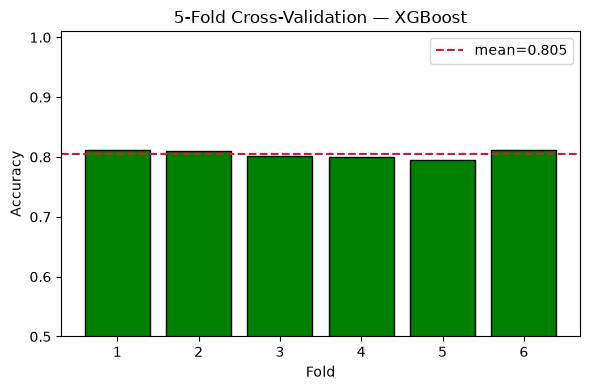

In [33]:
from sklearn.model_selection import cross_val_score

cv_acc = cross_val_score(pipe, X, y, cv=6, scoring="accuracy")
print("5-fold accuracy scores:", np.round(cv_acc, 3))
print(f"Mean: {cv_acc.mean():.3f}  Std: {cv_acc.std():.3f}")

plt.figure(figsize=(6, 4))
plt.bar(range(1, 7), cv_acc, color="green", edgecolor="black")
plt.axhline(cv_acc.mean(), color="crimson", ls="--", label=f"mean={cv_acc.mean():.3f}")
plt.xlabel("Fold")
plt.ylabel("Accuracy")
plt.title("5-Fold Cross-Validation — XGBoost")
plt.ylim(0.5, 1.01)
plt.legend()
plt.tight_layout()
plt.show()


## 5. Model Evaluation

In [37]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

pipe.fit(X_train, y_train)
proba = pipe.predict_proba(X_test)[:, 1]

print("ROC-AUC:", round(roc_auc_score(y_test, proba), 3))
print(classification_report(y_test, (proba >= 0.5).astype(int)))

ROC-AUC: 0.848
              precision    recall  f1-score   support

           0       0.84      0.91      0.88      1035
           1       0.69      0.53      0.60       374

    accuracy                           0.81      1409
   macro avg       0.76      0.72      0.74      1409
weighted avg       0.80      0.81      0.80      1409

